In [4]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [5]:
import zipfile
import os

zip_file = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/data')

os.listdir('/content/data')

['PS_20174392719_1491204439457_log.csv']

In [6]:
import os

os.listdir('/content/data')

['PS_20174392719_1491204439457_log.csv']

In [7]:
import pandas as pd
import os

files_list = os.listdir('/content/data')

csv_file = [f for f in files_list if f.endswith('.csv')][0]

df = pd.read_csv('/content/data/' + csv_file)

df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [8]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 6362620
Columns: 11


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [12]:
df.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
df = df.drop_duplicates()

print("Dataset after removing duplicates:", df.shape)

Dataset after removing duplicates: (6362620, 11)


In [15]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [16]:
df['amount'].mean()

np.float64(179861.90354913071)

In [17]:
df['amount'].median()

74871.94

In [18]:
df['amount'].std()

603858.2314629931

In [19]:
df['amount'].quantile([0.25, 0.50, 0.75])

,amount
0.25,13389.5700
0.50,74871.9400
0.75,208721.4775


In [20]:
df['amount'].quantile([0.90, 0.95, 0.99])

,amount
0.90,3.654233e+05
0.95,5.186342e+05
0.99,1.615979e+06


In [21]:
fraud_count = df['isFraud'].sum()
total_count = len(df)

fraud_percentage = (fraud_count / total_count) * 100

print("Total transactions:", total_count)
print("Fraud transactions:", fraud_count)
print("Fraud percentage:", round(fraud_percentage, 2), "%")

Total transactions: 6362620
Fraud transactions: 8213
Fraud percentage: 0.13 %


In [22]:
df['isFraud'].value_counts()

,count
isFraud,
0,6354407
1,8213


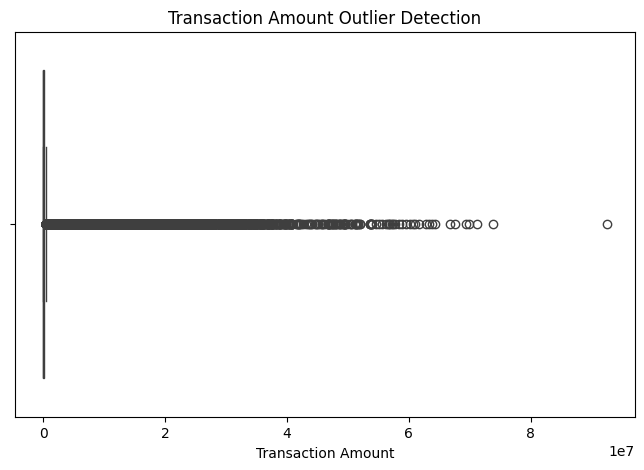

In [23]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df['amount'])

plt.title("Transaction Amount Outlier Detection")
plt.xlabel("Transaction Amount")

plt.show()

In [24]:
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 13389.57
Q3: 208721.4775
IQR: 195331.9075
Lower limit: -279608.29125
Upper limit: 501719.33875


In [25]:
outliers = df[
    (df['amount'] < lower_limit) |
    (df['amount'] > upper_limit)
]

print("Number of outliers:", len(outliers))

outliers.head()

Number of outliers: 338078


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
85,1,TRANSFER,1505626.01,C926859124,0.0,0.0,C665576141,29031.00,5515763.34,0,0
86,1,TRANSFER,554026.99,C1603696865,0.0,0.0,C766572210,579285.56,0.00,0,0
88,1,TRANSFER,761507.39,C412788346,0.0,0.0,C1590550415,1280036.23,19169204.93,0,0
89,1,TRANSFER,1429051.47,C1520267010,0.0,0.0,C1590550415,2041543.62,19169204.93,0,0
93,1,TRANSFER,583848.46,C1839168128,0.0,0.0,C1286084959,667778.00,2107778.11,0,0


In [26]:
from scipy.stats import zscore

df['amount_zscore'] = zscore(df['amount'])

z_outliers = df[df['amount_zscore'].abs() > 3]

print("Z-score outliers:", len(z_outliers))

Z-score outliers: 44945


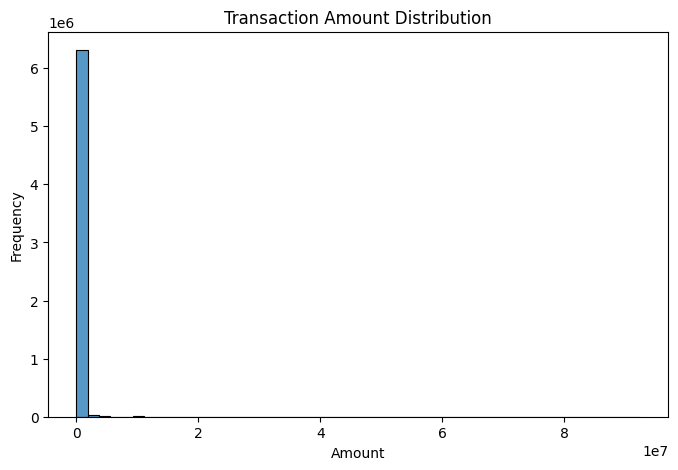

In [27]:
plt.figure(figsize=(8,5))

sns.histplot(df['amount'], bins=50)

plt.title("Transaction Amount Distribution")
plt.xlabel("Amount")
plt.ylabel("Frequency")

plt.show()

In [28]:
print("Fraud among IQR outliers:",
      outliers['isFraud'].sum())

print("Normal among IQR outliers:",
      (outliers['isFraud'] == 0).sum())

Fraud among IQR outliers: 3854
Normal among IQR outliers: 334224


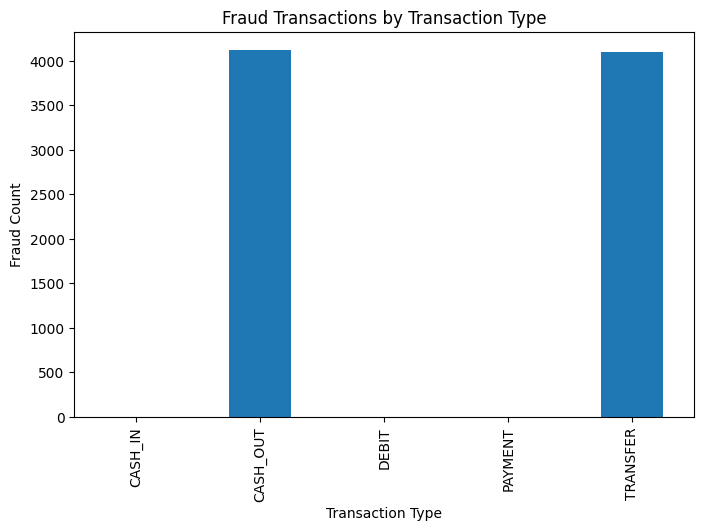

In [29]:
fraud_by_type = df.groupby('type')['isFraud'].sum()

fraud_by_type.plot(kind='bar', figsize=(8,5))

plt.title("Fraud Transactions by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Count")

plt.show()

type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64


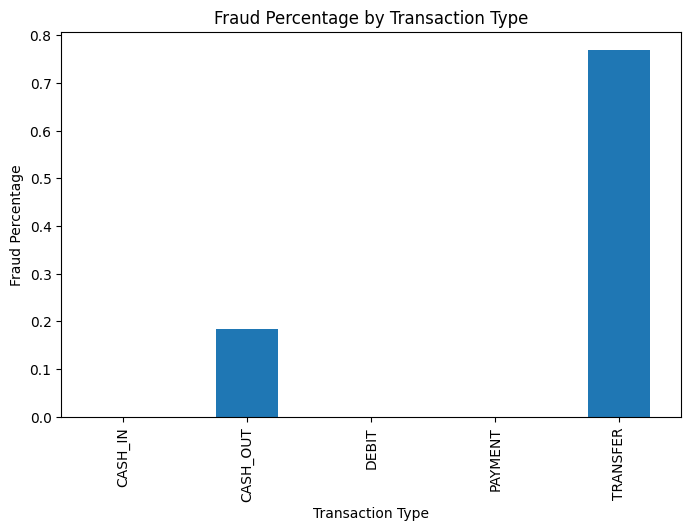

In [30]:
fraud_percentage_by_type = df.groupby('type')['isFraud'].mean() * 100

print(fraud_percentage_by_type)

fraud_percentage_by_type.plot(kind='bar', figsize=(8,5))

plt.title("Fraud Percentage by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Percentage")

plt.show()

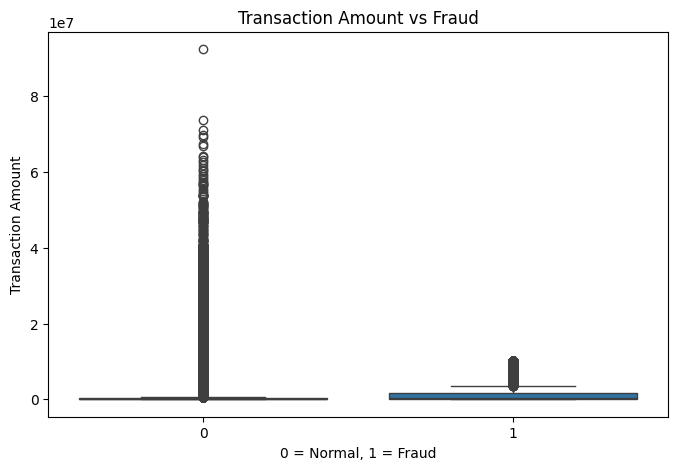

In [31]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='isFraud', y='amount')

plt.title("Transaction Amount vs Fraud")
plt.xlabel("0 = Normal, 1 = Fraud")
plt.ylabel("Transaction Amount")

plt.show()

type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64


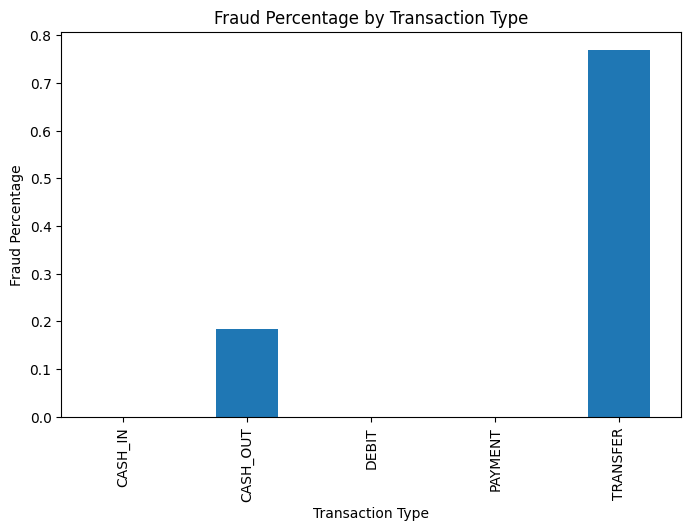

In [32]:
fraud_percentage_by_type = df.groupby('type')['isFraud'].mean() * 100

print(fraud_percentage_by_type)

fraud_percentage_by_type.plot(kind='bar', figsize=(8,5))

plt.title("Fraud Percentage by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Percentage")

plt.show()

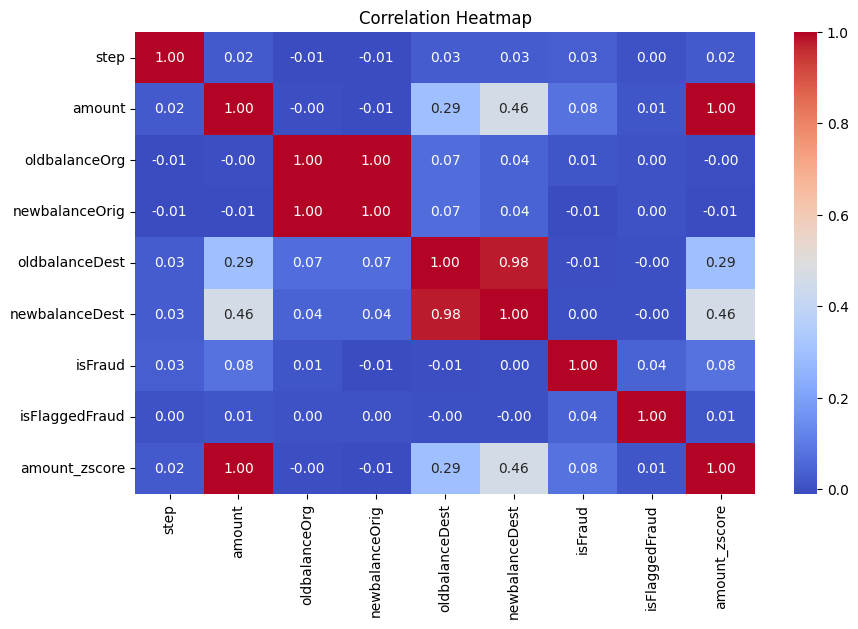

In [33]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(10,6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

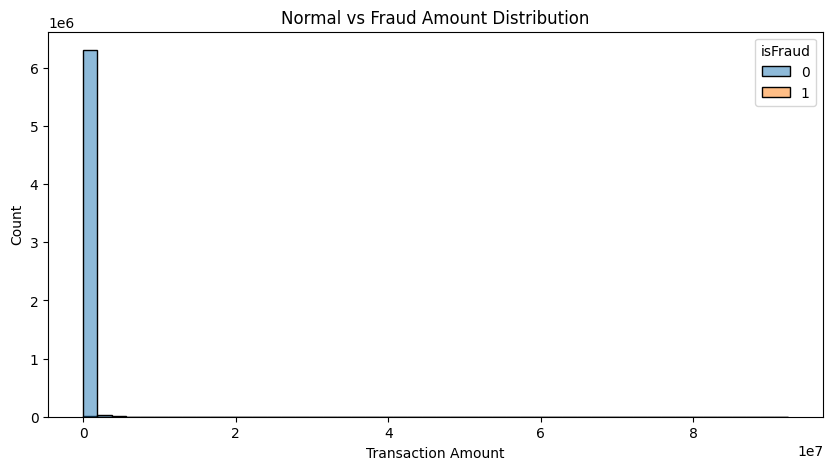

In [34]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='amount',
    hue='isFraud',
    bins=50
)

plt.title("Normal vs Fraud Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Count")

plt.show()

In [35]:
from scipy.stats import ttest_ind

normal_amount = df[df['isFraud'] == 0]['amount']
fraud_amount = df[df['isFraud'] == 1]['amount']

t_stat, p_value = ttest_ind(
    normal_amount,
    fraud_amount,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("Significant difference exists.")
else:
    print("Fail to reject Null Hypothesis")
    print("No significant difference found.")

T-Statistic: -48.61450320422931
P-Value: 0.0
Reject Null Hypothesis
Significant difference exists.


In [36]:
print("Normal Transaction Mean:", normal_amount.mean())
print("Fraud Transaction Mean:", fraud_amount.mean())

Normal Transaction Mean: 178197.0417274075
Fraud Transaction Mean: 1467967.2991403872


In [37]:
if p_value < 0.05:
    print("Business Interpretation:")
    print("Fraud and normal transactions have statistically different average amounts.")
else:
    print("Business Interpretation:")
    print("We did not find sufficient statistical evidence of a difference in average amounts.")

Business Interpretation:
Fraud and normal transactions have statistically different average amounts.


In [38]:
fraud_transactions = df[df['isFraud'] == 1]

print("===== FRAUD SIGNAL REPORT =====")

print("Total Transactions:", len(df))
print("Total Fraud Transactions:", len(fraud_transactions))

print("Average Fraud Amount:",
      fraud_transactions['amount'].mean())

print("Maximum Fraud Amount:",
      fraud_transactions['amount'].max())

print("\nFraud by Transaction Type:")
print(fraud_transactions['type'].value_counts())

print("\nFraud among IQR outliers:")
print(outliers['isFraud'].sum())

===== FRAUD SIGNAL REPORT =====
Total Transactions: 6362620
Total Fraud Transactions: 8213
Average Fraud Amount: 1467967.2991403872
Maximum Fraud Amount: 10000000.0

Fraud by Transaction Type:
type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64

Fraud among IQR outliers:
3854


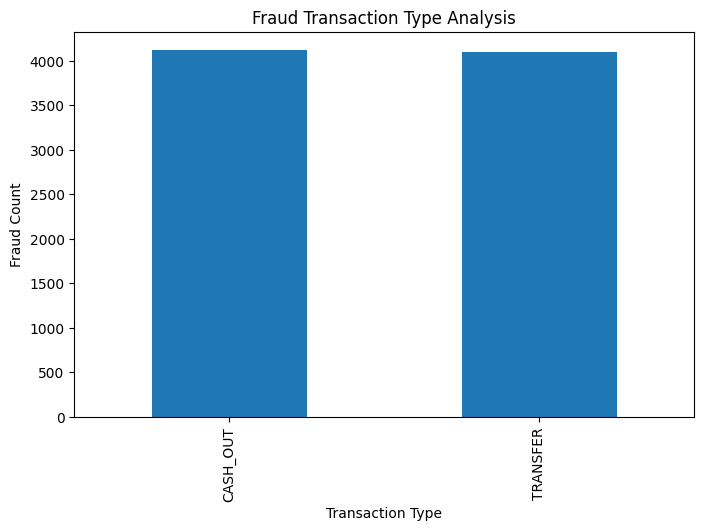

In [39]:
fraud_transactions['type'].value_counts().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Fraud Transaction Type Analysis")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Count")

plt.show()

In [40]:
print("===== FINAL BUSINESS SUMMARY =====")

print("Total Transactions:", len(df))

print("Fraud Count:", df['isFraud'].sum())

print("Fraud Percentage:",
      round(df['isFraud'].mean() * 100, 2), "%")

print("Average Transaction Amount:",
      round(df['amount'].mean(), 2))

print("Average Fraud Amount:",
      round(fraud_transactions['amount'].mean(), 2))

print("Highest Fraud Amount:",
      fraud_transactions['amount'].max())

print("Most common Fraud Type:",
      fraud_transactions['type'].mode()[0])

===== FINAL BUSINESS SUMMARY =====
Total Transactions: 6362620
Fraud Count: 8213
Fraud Percentage: 0.13 %
Average Transaction Amount: 179861.9
Average Fraud Amount: 1467967.3
Highest Fraud Amount: 10000000.0
Most common Fraud Type: CASH_OUT


In [41]:
print("===== BUSINESS RECOMMENDATIONS =====")

print("1. Monitor high-value transactions.")
print("2. Investigate unusual transaction patterns.")
print("3. Monitor suspicious transaction types.")
print("4. Review statistical outliers.")
print("5. Use multiple signals for fraud detection.")

===== BUSINESS RECOMMENDATIONS =====
1. Monitor high-value transactions.
2. Investigate unusual transaction patterns.
3. Monitor suspicious transaction types.
4. Review statistical outliers.
5. Use multiple signals for fraud detection.


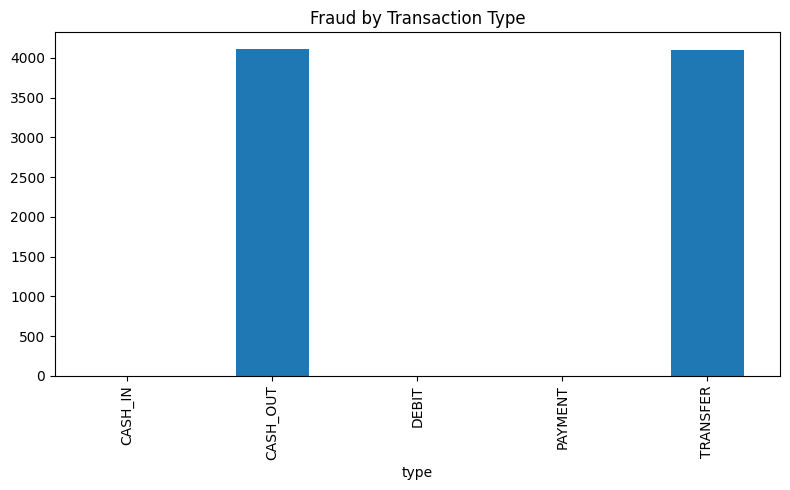

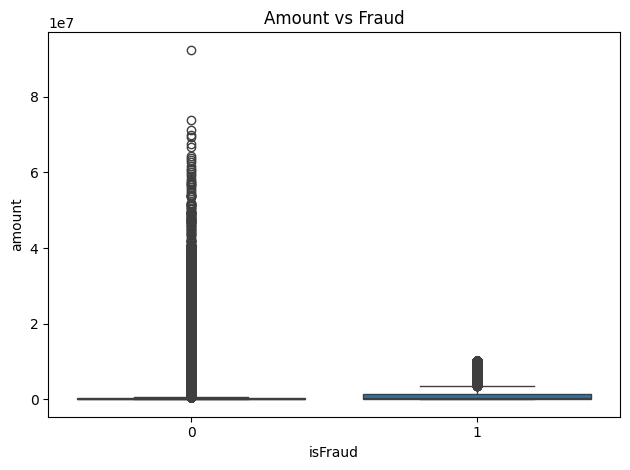

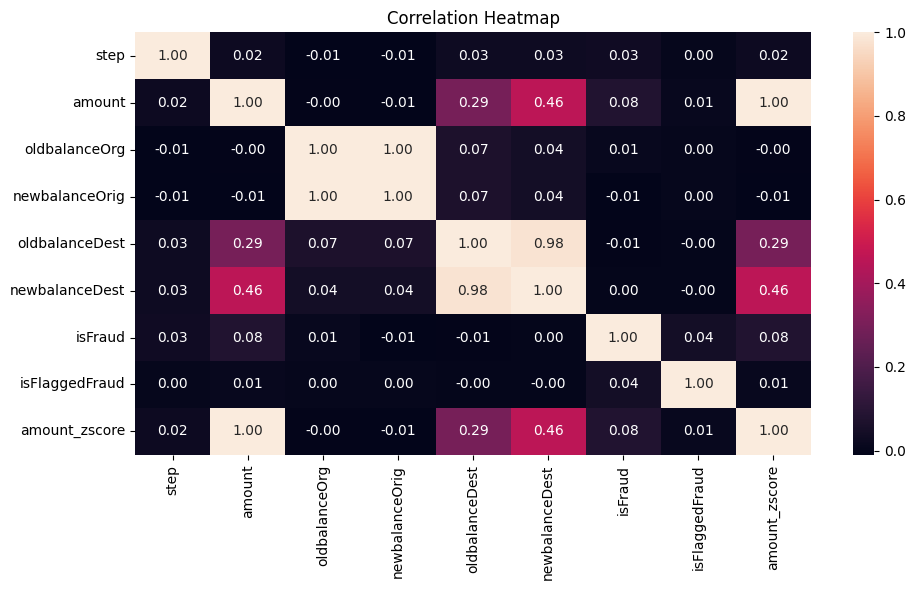

Graphs saved in images folder!


In [42]:
import os

os.makedirs("images", exist_ok=True)

# Fraud by transaction type
fraud_by_type.plot(kind='bar', figsize=(8,5))
plt.title("Fraud by Transaction Type")
plt.tight_layout()
plt.savefig("images/fraud_by_type.png")
plt.show()
plt.close()

# Amount boxplot
sns.boxplot(data=df, x='isFraud', y='amount')
plt.title("Amount vs Fraud")
plt.tight_layout()
plt.savefig("images/amount_vs_fraud.png")
plt.show()
plt.close()

# Correlation heatmap
plt.figure(figsize=(10,6))
sns.heatmap(df.select_dtypes(include='number').corr(),
            annot=True, fmt='.2f')
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("images/heatmap.png")
plt.show()
plt.close()

print("Graphs saved in images folder!")

In [43]:
fraud_pct = df['isFraud'].mean() * 100
normal_mean = df[df['isFraud'] == 0]['amount'].mean()
fraud_mean = df[df['isFraud'] == 1]['amount'].mean()

print("===== CONCLUSION =====")
print(f"Total transactions: {len(df)}")
print(f"Fraud transactions: {df['isFraud'].sum()}")
print(f"Fraud percentage: {fraud_pct:.2f}%")
print(f"Normal average amount: {normal_mean:.2f}")
print(f"Fraud average amount: {fraud_mean:.2f}")

if fraud_mean > normal_mean:
    print("Fraud transactions have a higher average amount.")
else:
    print("Fraud transactions do not have a higher average amount.")

print("Statistical analysis can help identify unusual transaction patterns.")
print("Outliers require investigation and are not automatically fraud.")

===== CONCLUSION =====
Total transactions: 6362620
Fraud transactions: 8213
Fraud percentage: 0.13%
Normal average amount: 178197.04
Fraud average amount: 1467967.30
Fraud transactions have a higher average amount.
Statistical analysis can help identify unusual transaction patterns.
Outliers require investigation and are not automatically fraud.


Conclusion

This project analyzed digital financial transactions using statistical methods to identify unusual patterns that may indicate fraud.

The analysis included data understanding, descriptive statistics, outlier detection, pattern analysis, and hypothesis testing.

Transaction amounts and transaction types were explored to understand possible fraud indicators. Outlier detection methods such as IQR and Z-score were used to identify unusual transactions. A statistical hypothesis test was also performed to compare normal and fraudulent transaction amounts.

Business Recommendations

- Monitor unusual high-value transactions.
- Investigate statistically unusual transactions.
- Monitor transaction types that show higher fraud activity.
- Use multiple statistical indicators during fraud investigation.
- Do not classify every outlier as fraud without further investigation.

Limitations

The dataset is synthetic and does not contain all real-world UPI characteristics. Device changes, actual clock time, and account age were not available for this analysis.

Future Scope

Machine learning models can be developed to improve fraud detection. Additional real-world features such as device information, location, account age, and transaction frequency could improve future analysis.